#**Setup**

In [110]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [111]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [112]:
PATH = '/content/drive/MyDrive/digital_wallet_transactions.csv'  # change to your folder
df = pd.read_csv(PATH)

# **Data Exploration**

In [113]:
df.head()

,idx,transaction_id,user_id,transaction_date,product_category,product_name,merchant_name,product_amount,transaction_fee,cashback,loyalty_points,payment_method,transaction_status,merchant_id,device_type,location
0,1,4dac3ea3-6492-46ec-80b8-dc45c3ad0b14,USER_05159,2023-08-19 03:32,Rent Payment,2BHK Flat Deposit,Airbnb,1525.39,36.69,19.19,186,Debit Card,Successful,MERCH_0083,iOS,Urban
1,2,a903ed9f-eb84-47e7-b8aa-fd1786c919cf,USER_07204,2023-08-19 04:37,Gas Bill,Commercial Gas Connection,Adani Gas,1495.40,28.19,89.99,182,UPI,Successful,MERCH_0163,iOS,Urban
2,3,2a393013-733c-4add-9f09-bed1eeb33676,USER_00903,2023-08-19 05:52,Bus Ticket,Semi-Sleeper,MakeMyTrip Bus,1267.71,11.36,95.70,994,UPI,Successful,MERCH_0320,iOS,Urban
3,4,9a07ad19-4673-4794-9cd2-9b139f39c715,USER_01769,2023-08-19 06:35,Internet Bill,4G Unlimited Plan,Airtel Broadband,9202.63,6.41,82.24,409,Debit Card,Successful,MERCH_0194,Android,Urban
4,5,76418260-c985-4011-979d-0914604d0d68,USER_03544,2023-08-19 06:36,Loan Repayment,Home Loan EMI,Axis Bank,3100.58,41.15,40.47,837,Debit Card,Successful,MERCH_0504,Android,Urban


In [114]:
df.shape

(5000, 16)

In [115]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   idx                 5000 non-null   int64  
 1   transaction_id      5000 non-null   object 
 2   user_id             5000 non-null   object 
 3   transaction_date    5000 non-null   object 
 4   product_category    5000 non-null   object 
 5   product_name        5000 non-null   object 
 6   merchant_name       5000 non-null   object 
 7   product_amount      5000 non-null   float64
 8   transaction_fee     5000 non-null   float64
 9   cashback            5000 non-null   float64
 10  loyalty_points      5000 non-null   int64  
 11  payment_method      5000 non-null   object 
 12  transaction_status  5000 non-null   object 
 13  merchant_id         5000 non-null   object 
 14  device_type         5000 non-null   object 
 15  location            5000 non-null   object 
dtypes: flo

In [116]:
categorical_cols = ['product_category', 'payment_method', 'transaction_status', 'device_type', 'location']
for col in categorical_cols:
    if col in df.columns:
        print(f"Distinct values in '{col}':")
        print(df[col].unique())
        print("-" * 40)

Distinct values in 'product_category':
['Rent Payment' 'Gas Bill' 'Bus Ticket' 'Internet Bill' 'Loan Repayment'
 'Flight Booking' 'Hotel Booking' 'Insurance Premium' 'Online Shopping'
 'Mobile Recharge' 'Electricity Bill' 'Streaming Service'
 'Grocery Shopping' 'Taxi Fare' 'Gaming Credits' 'Water Bill'
 'Movie Ticket' 'Food Delivery' 'Gift Card' 'Education Fee']
----------------------------------------
Distinct values in 'payment_method':
['Debit Card' 'UPI' 'Wallet Balance' 'Credit Card' 'Bank Transfer']
----------------------------------------
Distinct values in 'transaction_status':
['Successful' 'Failed' 'Pending']
----------------------------------------
Distinct values in 'device_type':
['iOS' 'Android' 'Web']
----------------------------------------
Distinct values in 'location':
['Urban' 'Suburban' 'Rural']
----------------------------------------


# **Data Preprocessing**

In [117]:
print(df.duplicated().sum())

0


In [118]:
df.drop(columns=['idx'], inplace=True, errors='ignore')

In [119]:
df['transaction_date'] = pd.to_datetime(df['transaction_date'])
df['month'] = df['transaction_date'].dt.month
df['weekday'] = df['transaction_date'].dt.weekday
df['hour'] = df['transaction_date'].dt.hour
df['is_weekend'] = df['weekday'].isin([5, 6]).astype(int)
df[['transaction_date', 'month', 'weekday', 'hour', 'is_weekend']].head()

,transaction_date,month,weekday,hour,is_weekend
0,2023-08-19 03:32:00,8,5,3,1
1,2023-08-19 04:37:00,8,5,4,1
2,2023-08-19 05:52:00,8,5,5,1
3,2023-08-19 06:35:00,8,5,6,1
4,2023-08-19 06:36:00,8,5,6,1


In [120]:
df.head()

,transaction_id,user_id,transaction_date,product_category,product_name,merchant_name,product_amount,transaction_fee,cashback,loyalty_points,payment_method,transaction_status,merchant_id,device_type,location,month,weekday,hour,is_weekend
0,4dac3ea3-6492-46ec-80b8-dc45c3ad0b14,USER_05159,2023-08-19 03:32:00,Rent Payment,2BHK Flat Deposit,Airbnb,1525.39,36.69,19.19,186,Debit Card,Successful,MERCH_0083,iOS,Urban,8,5,3,1
1,a903ed9f-eb84-47e7-b8aa-fd1786c919cf,USER_07204,2023-08-19 04:37:00,Gas Bill,Commercial Gas Connection,Adani Gas,1495.40,28.19,89.99,182,UPI,Successful,MERCH_0163,iOS,Urban,8,5,4,1
2,2a393013-733c-4add-9f09-bed1eeb33676,USER_00903,2023-08-19 05:52:00,Bus Ticket,Semi-Sleeper,MakeMyTrip Bus,1267.71,11.36,95.70,994,UPI,Successful,MERCH_0320,iOS,Urban,8,5,5,1
3,9a07ad19-4673-4794-9cd2-9b139f39c715,USER_01769,2023-08-19 06:35:00,Internet Bill,4G Unlimited Plan,Airtel Broadband,9202.63,6.41,82.24,409,Debit Card,Successful,MERCH_0194,Android,Urban,8,5,6,1
4,76418260-c985-4011-979d-0914604d0d68,USER_03544,2023-08-19 06:36:00,Loan Repayment,Home Loan EMI,Axis Bank,3100.58,41.15,40.47,837,Debit Card,Successful,MERCH_0504,Android,Urban,8,5,6,1


# **Data Visualization**

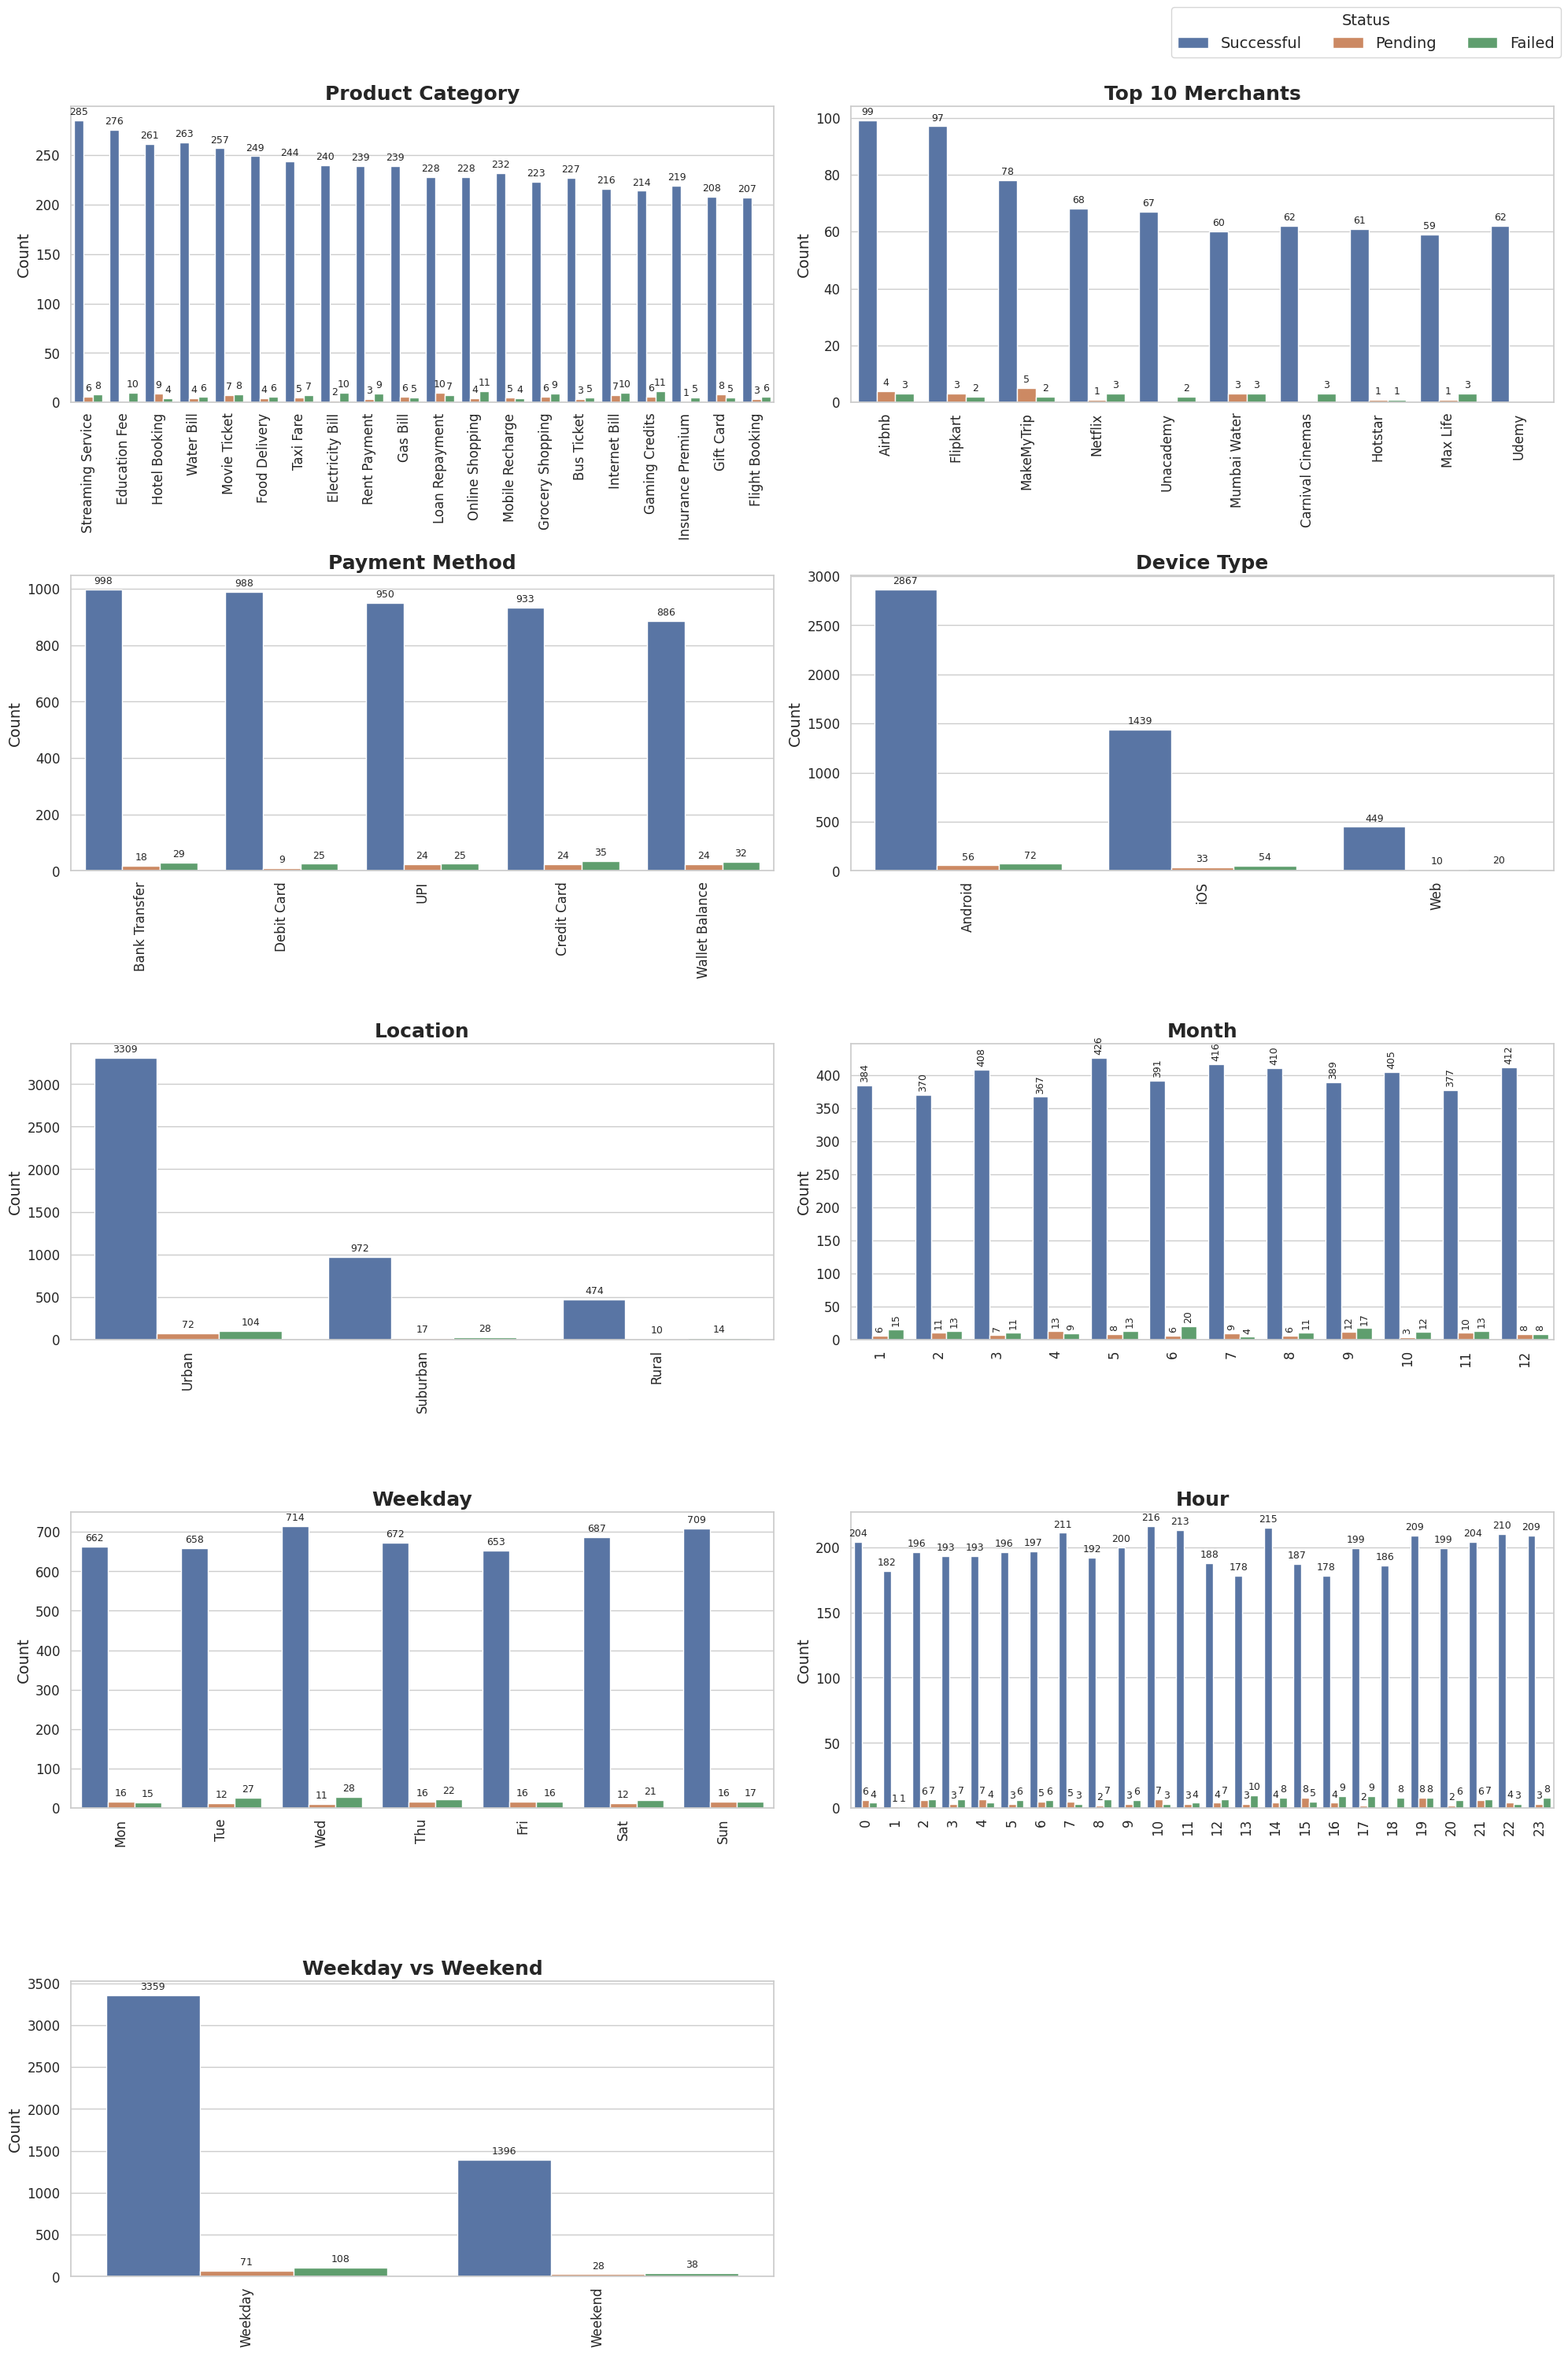

In [127]:
plot_df = df.copy()
plot_df['weekday'] = plot_df['weekday'].map(dict(enumerate(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])))
plot_df['is_weekend'] = plot_df['is_weekend'].map({0: 'Weekday', 1: 'Weekend'})

# ---- SIZE: change these two numbers (width, height in inches) ----
fig, axes = plt.subplots(5, 2, figsize=(20, 30))
axes = axes.flatten()

# (column, title)   transaction_status is the grouping, so it is not plotted on its own
features = [
    ('product_category', 'Product Category'),
    ('merchant_name', 'Top 10 Merchants'),
    ('payment_method', 'Payment Method'),
    ('device_type', 'Device Type'),
    ('location', 'Location'),
    ('month', 'Month'),
    ('weekday', 'Weekday'),
    ('hour', 'Hour'),
    ('is_weekend', 'Weekday vs Weekend'),
]

status_order = ['Successful', 'Pending', 'Failed']

for ax, (col, title) in zip(axes, features):
    if col == 'merchant_name':
        order = plot_df[col].value_counts().nlargest(10).index
    elif col in ['month', 'hour']:
        order = sorted(plot_df[col].unique())
    elif col == 'weekday':
        order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
    else:
        order = plot_df[col].value_counts().index

    sns.countplot(data=plot_df, x=col, order=order, ax=ax, hue='transaction_status', hue_order=status_order)
    ax.set_title(title, fontsize=18, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Count', fontsize=14)
    ax.tick_params(axis='x', rotation=90, labelsize=12)
    ax.tick_params(axis='y', labelsize=12)
    handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()   # one shared legend is added at the top instead

    # Display numbers on top of the bars
    for container in ax.containers:
        ax.bar_label(container, fontsize=9, padding=3, rotation=90 if col in ['month'] else 0)

axes[-1].axis('off')   # hide the empty 10th panel
fig.legend(handles, labels, title='Status', loc='upper right', ncol=3, fontsize=14, title_fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

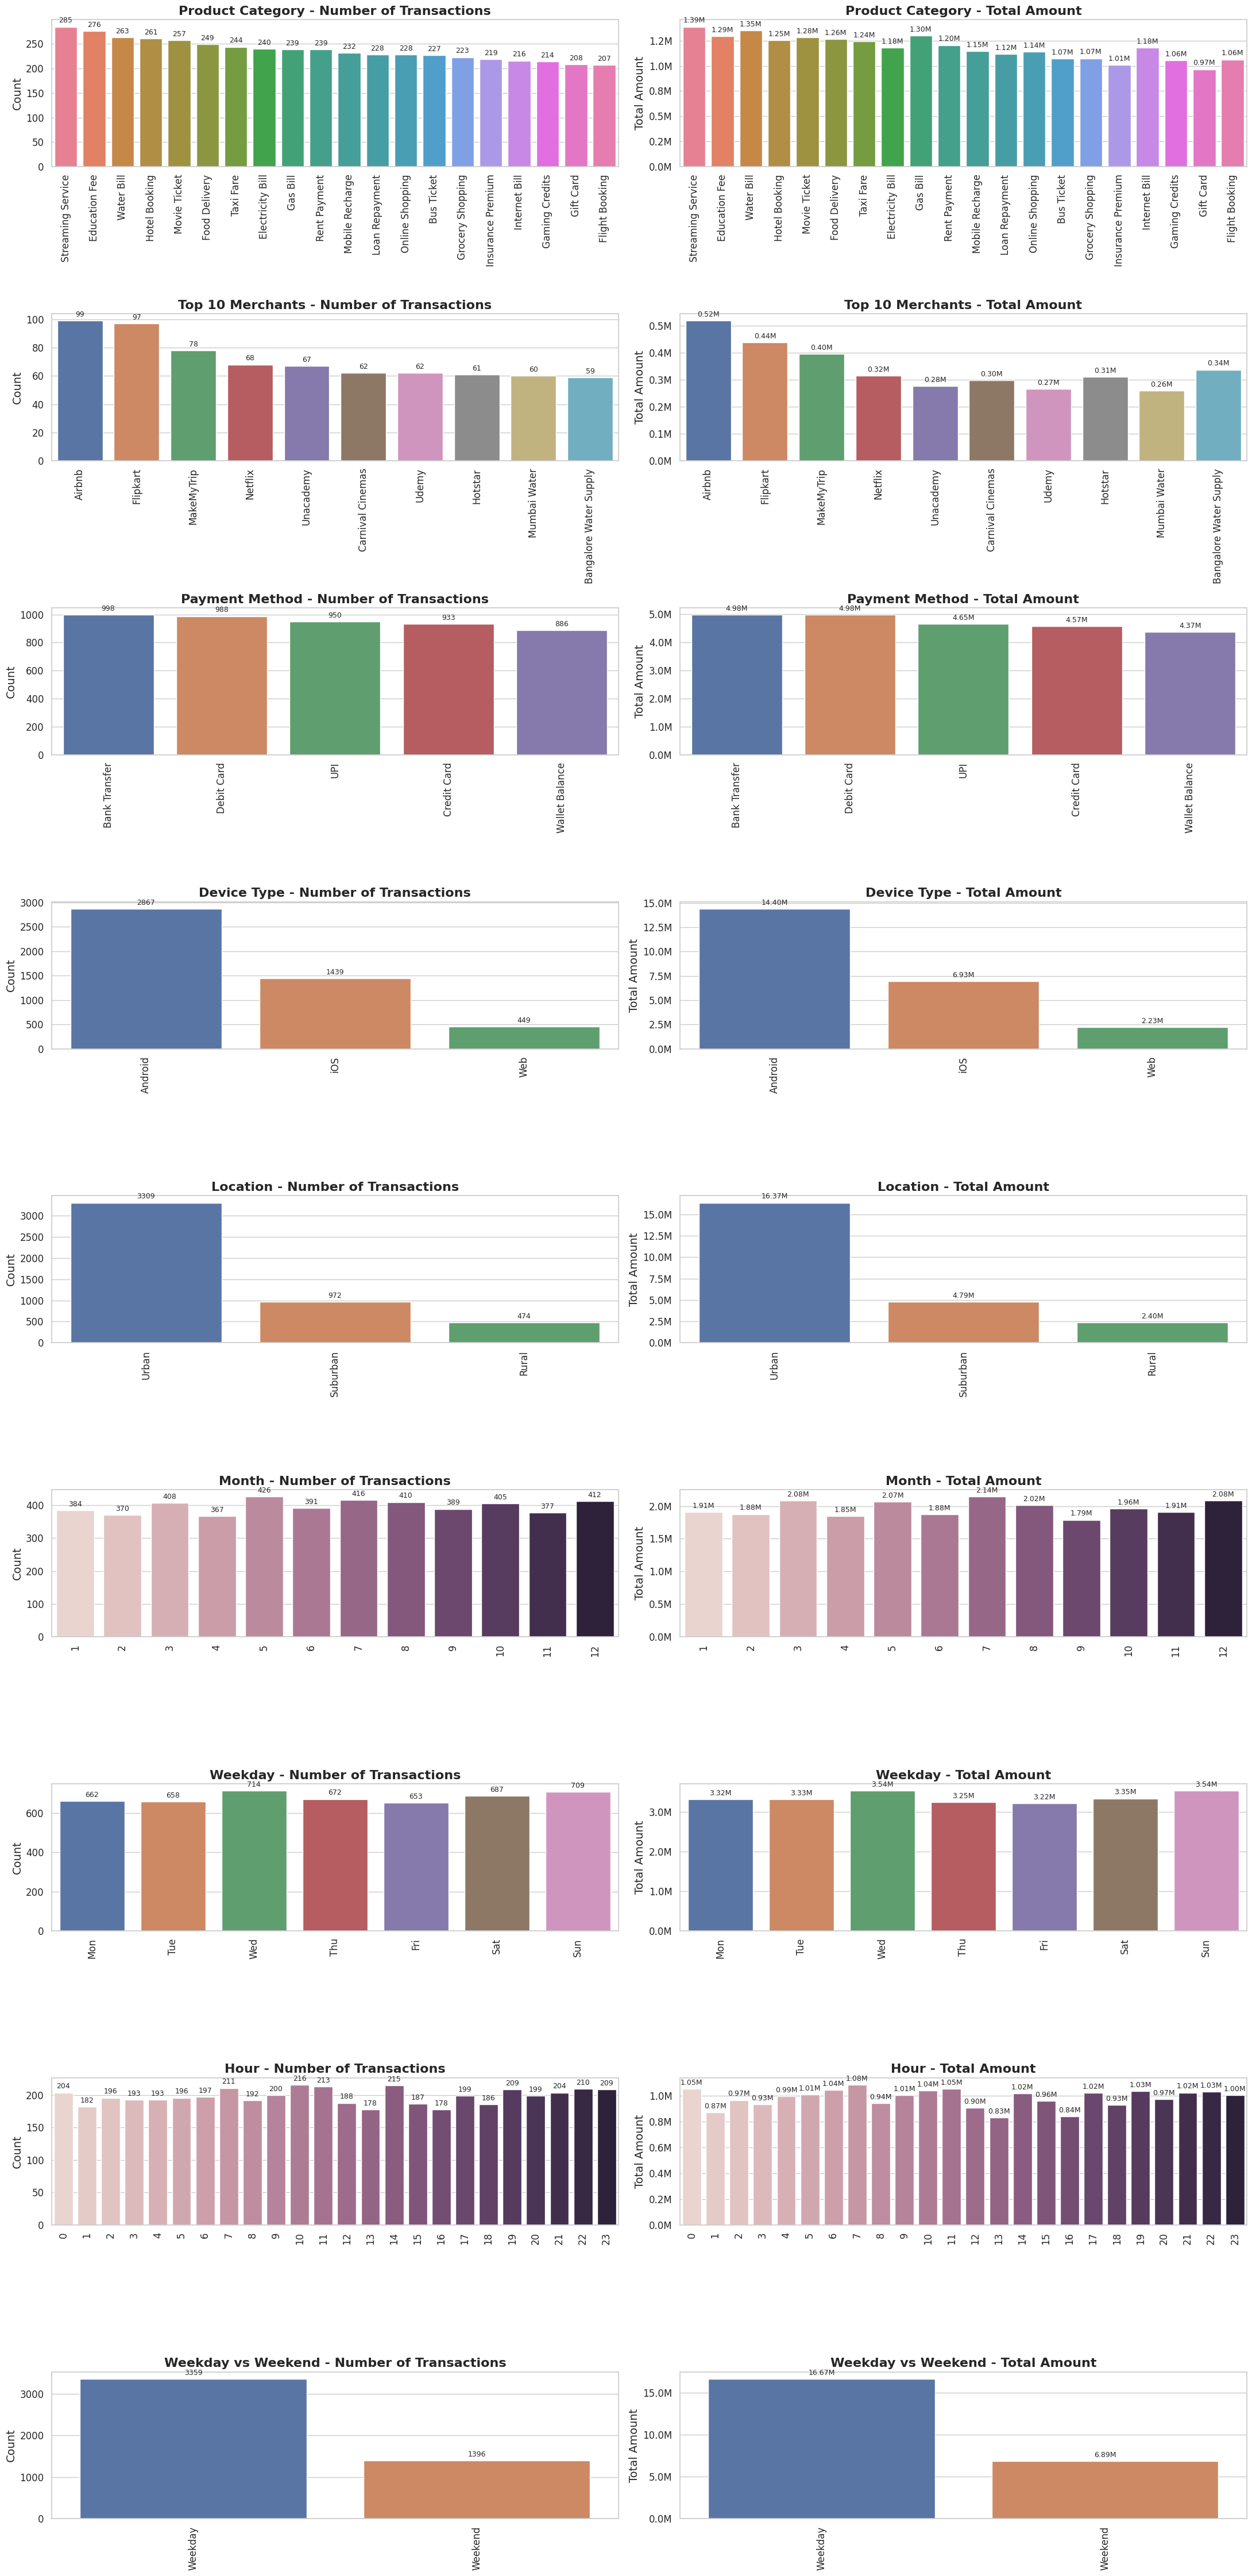

In [128]:
# True = successful transactions only, False = all transactions
SUCCESS_ONLY = True
if SUCCESS_ONLY:
    plot_df = plot_df[plot_df['transaction_status'] == 'Successful']

# (column, title)
features = [
    ('product_category', 'Product Category'),
    ('merchant_name', 'Top 10 Merchants'),
    ('payment_method', 'Payment Method'),
    ('transaction_status', 'Transaction Status'),
    ('device_type', 'Device Type'),
    ('location', 'Location'),
    ('month', 'Month'),
    ('weekday', 'Weekday'),
    ('hour', 'Hour'),
    ('is_weekend', 'Weekday vs Weekend'),
]
# status has only 1 bar when filtered, so skip it
features = [f for f in features if not (SUCCESS_ONLY and f[0] == 'transaction_status')]

# ---- SIZE: change these two numbers (width, height in inches) ----
fig, axes = plt.subplots(len(features), 2, figsize=(22, 5 * len(features)))

for row, (col, title) in enumerate(features):
    ax_count, ax_amount = axes[row]

    # same order on both sides so bars line up for comparison
    if col == 'merchant_name':
        order = plot_df[col].value_counts().nlargest(10).index
    elif col in ['month', 'hour']:
        order = sorted(plot_df[col].unique())
    elif col == 'weekday':
        order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
    else:
        order = plot_df[col].value_counts().index

    # LEFT: number of transactions
    sns.countplot(data=plot_df, x=col, order=order, ax=ax_count, hue=col, hue_order=order, legend=False)
    ax_count.set_title(f'{title} - Number of Transactions', fontsize=16, fontweight='bold')
    ax_count.set_ylabel('Count', fontsize=14)
    for container in ax_count.containers:
        ax_count.bar_label(container, fontsize=9, padding=3)

    # RIGHT: total amount
    sns.barplot(data=plot_df, x=col, y='product_amount', order=order, ax=ax_amount,
                estimator='sum', errorbar=None, hue=col, hue_order=order, legend=False)
    ax_amount.set_title(f'{title} - Total Amount', fontsize=16, fontweight='bold')
    ax_amount.set_ylabel('Total Amount', fontsize=14)
    ax_amount.yaxis.set_major_formatter(lambda x, pos: f'{x / 1e6:.1f}M')
    for container in ax_amount.containers:
        labels = [f'{v / 1e6:.2f}M' for v in container.datavalues]
        ax_amount.bar_label(container, labels=labels, fontsize=9, padding=3)

    for ax in (ax_count, ax_amount):
        ax.set_xlabel('')
        ax.tick_params(axis='x', rotation=90, labelsize=12)
        ax.tick_params(axis='y', labelsize=12)

plt.tight_layout()
plt.show()

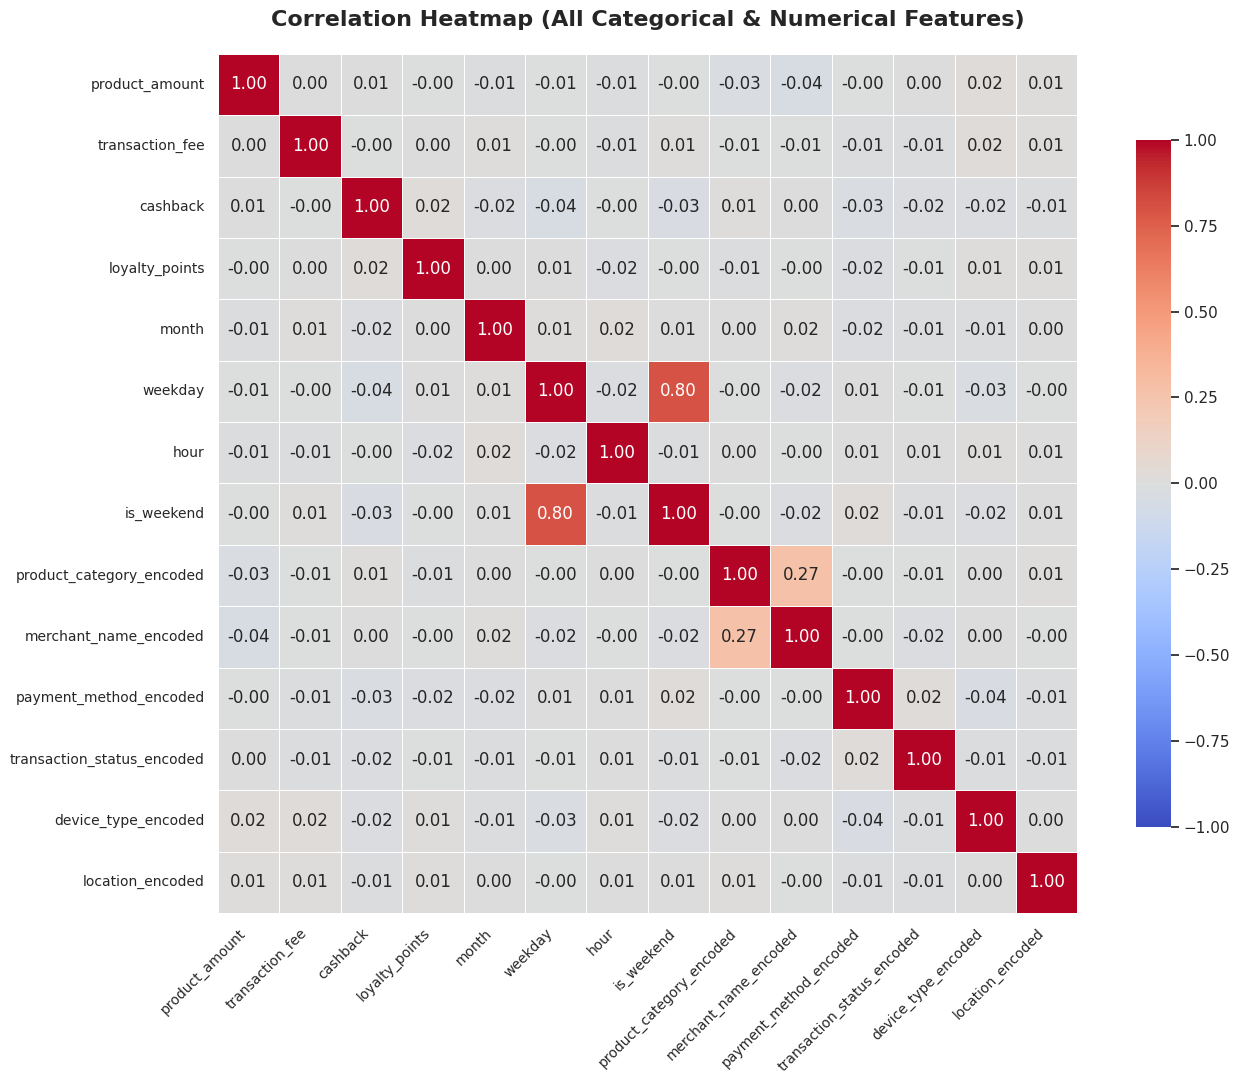

In [102]:
# Create a copy of the dataframe to encode categorical variables
corr_df = df.copy()

# List of categorical columns to encode
cats_to_encode = ['product_category', 'merchant_name', 'payment_method', 'transaction_status', 'device_type', 'location']

# Encode categorical columns numerically using factorize
for col in cats_to_encode:
    if col in corr_df.columns:
        corr_df[col] = corr_df[col].astype(str)
        corr_df[col + '_encoded'] = corr_df[col].factorize()[0]

# Define the full list of numerical and encoded categorical columns for correlation
all_features = [
    'product_amount', 'transaction_fee', 'cashback', 'loyalty_points',
    'month', 'weekday', 'hour', 'is_weekend',
    'product_category_encoded', 'merchant_name_encoded',
    'payment_method_encoded', 'transaction_status_encoded',
    'device_type_encoded', 'location_encoded'
]

# Compute correlation matrix
corr_matrix_all = corr_df[all_features].corr()

# Set up the matplotlib figure
plt.figure(figsize=(14, 11))

# Draw the heatmap with values and diverging color map
sns.heatmap(
    corr_matrix_all,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

plt.title("Correlation Heatmap (All Categorical & Numerical Features)", fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

# **Data Analysis**

**Key Findings**
1. **Transaction status is mostly unrelated to other variables.** Correlation analysis shows no meaningful relationships.
2. **Number of transactions and total amount follow the same pattern.** No group has few transactions but a large total amount.
3. **No clear trend over time or category.** Product category, payment method, month, weekday and hour are almost flat.
4. **Online merchants dominate.** 7 of the top 10 merchants are digital (Airbnb, Flipkart, MakeMyTrip, Netflix, Unacademy, Hotstar, Udemy), where there is no physical shop to pay at.
5. **Android leads, Web is smallest.** Android has about 60% of transactions, iOS 31% and Web 10%.
6. **Usage falls from urban to rural.** Urban has about 70% of transactions, suburban 20% and rural 10%.

**Possible reasons (hypotheses, not proven by this data)**
- Digital merchants suit a wallet because payment must be made online.
- Android has more phone variety and a larger user base. Web needs a computer, while a phone app can be installed directly.
- Urban users rely more on the internet and have a more modern lifestyle.

**Recommendations**
1. **Prioritise the Android and iOS apps.** They carry about 90% of transactions, so reliability and features there have the biggest impact.
2. **Partner with more online merchants** in travel, streaming and education, which already drive the most transactions.

# **Dataset**

https://www.kaggle.com/datasets/harunrai/digital-wallet-transactions



In [130]:
df.to_csv('/content/drive/MyDrive/wallet_cleaned.csv', index=False)